# ⚛ Stage 5 — Interactive Q-Atlas

**Qubitrade · Quantum Market Memory for Explainable Alpha**

> The full end-to-end interactive demo.
> Ask any question about any ticker → quantum KNN retrieves top-5 analogous regimes → Gemini explains why.

**Architecture:**

```
User query: "Why is NVDA moving?"
        │
        ▼
  ZZFeatureMap 4-qubit quantum kernel
  ── signal space KNN ──────────────────────▶  top-5 analog dates
        │
        ▼
  Joint signal + news latent space (8D)
  4D signals + Gemini text-embedding-004 → PCA 4D
  ── joint space KNN ───────────────────────▶  analog news context
        │
        ▼
  Gemini 2.5 Flash synthesises:
  [WHY]    plausible fundamental/macro reason
  [SIGNAL] bull/bear/neutral + probability
  [RISK]   downside risk from analogous episodes
```

**⚛ Quantum hardware:** xpyq cloud QPU (real QPU, not simulation)
**Demo cells:** circuit diagram · NVDA live demo · xpyq comparison · quantum vs classical · batch queries · interactive `ask_qatlas()`


In [44]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
warnings.filterwarnings('ignore')

# Add UI directory so we can import the engine
UI_DIR = '/Applications/Projects/Hackathons/quantum_ai/ui'
sys.path.insert(0, UI_DIR)

from q_atlas_engine import QAtlasEngine, STATE_FEATURES

plt.style.use('dark_background')
plt.rcParams.update({'font.family': 'monospace', 'figure.facecolor': '#0d1117', 'axes.facecolor': '#161b22'})

print('Imports OK. Initialising Q-Atlas engine…')

Imports OK. Initialising Q-Atlas engine…


In [45]:
# Initialise engine — loads master_dataset, builds per-ticker indices, loads quantum kernel
engine = QAtlasEngine()

print(f'\nUniverse ({len(engine.tickers)} tickers):')
print(' '.join(engine.tickers))
print(f'\nDate range: {engine.date_min.date()} → {engine.date_max.date()}')
print(f'State features (4D → 4 qubits): {STATE_FEATURES}')

Q-Atlas engine ready | 20 tickers | kernel: xpyq remote

Universe (20 tickers):
AAPL BA BAC CAT CVX GOOGL JNJ JPM KO LLY MA MSFT NVDA PEP PFE PG UNH V WMT XOM

Date range: 2013-01-02 → 2020-06-10
State features (4D → 4 qubits): ['vol_20d', 'news_sent', 'mom_20d', 'dist_to_high']


## 1. Quantum circuit — ZZFeatureMap

In [46]:
from qiskit.circuit.library import ZZFeatureMap

fm = ZZFeatureMap(feature_dimension=4, reps=2, entanglement='linear')
print('ZZFeatureMap circuit:')
print(fm.decompose())
print(f'\nDepth: {fm.decompose().depth()} | Gates: {fm.decompose().count_ops()}')
print(f'Parameters: {fm.num_parameters} (one per feature per rep = 4×2)')
print()
print('How it works:')
print('  H gates       → superposition (all 2^4 = 16 basis states)')
print('  Rz(φᵢ)        → encodes feature φᵢ as rotation angle')
print('  Rzz(φᵢ·φⱼ)   → encodes INTERACTION between features i,j (entanglement)')
print('  Fidelity K    → ⟨ψ(x)|ψ(x\')⟩² = quantum kernel similarity')

ZZFeatureMap circuit:
     ┌───┐┌───────────┐                                        ┌───┐»
q_0: ┤ H ├┤ P(2*x[0]) ├──■──────────────────────────────────■──┤ H ├»
     ├───┤├───────────┤┌─┴─┐┌────────────────────────────┐┌─┴─┐└───┘»
q_1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P(2*(π - x[0])*(π - x[1])) ├┤ X ├──■──»
     ├───┤├───────────┤└───┘└────────────────────────────┘└───┘┌─┴─┐»
q_2: ┤ H ├┤ P(2*x[2]) ├────────────────────────────────────────┤ X ├»
     ├───┤├───────────┤                                        └───┘»
q_3: ┤ H ├┤ P(2*x[3]) ├─────────────────────────────────────────────»
     └───┘└───────────┘                                             »
«             ┌───────────┐                                                 »
«q_0: ────────┤ P(2*x[0]) ├─────────────────────────────────────────────────»
«             └───────────┘              ┌───┐        ┌───────────┐         »
«q_1: ────────────────────────────────■──┤ H ├────────┤ P(2*x[1]) ├─────────»
«     ┌────────────────────────────┐

## 2. Live demo — "Why is NVDA moving?"

In [47]:
QUERY_TEXT = 'Why is NVDA moving?'

# Parse ticker
ticker, confidence = engine.parse_ticker(QUERY_TEXT)
print(f'Query: "{QUERY_TEXT}"')
print(f'Parsed: ticker={ticker}  (confidence={confidence})')
print()

# Run quantum KNN
print(f'Running quantum kernel KNN for {ticker}…')
t0 = time.time()
result, err = engine.query(ticker, top_k=5)
if err:
    print(f'Error: {err}')
else:
    qs = result['query_state']
    print(f'Query date: {pd.Timestamp(result["query_date"]).strftime("%Y-%m-%d")}')
    print(f'Candidates scanned: {result["n_candidates"]:,}')
    print(f'Kernel time: {result["kernel_time"]:.2f}s')
    print()
    print(f'Current {ticker} state:')
    for f in STATE_FEATURES:
        print(f'  {f:20s} = {qs.get(f, 0):+.4f}')
    print(f'  {"regime":20s} = {qs.get("regime", "unknown")}')
    print()
    print(f'Top-5 quantum analog regimes:')
    print('-' * 64)
    for a in result['analogs']:
        ctx = a['context']
        fwd5 = ctx.get('fwd_return_5d', 0) * 100
        ret1 = ctx.get('return_1d', 0) * 100
        print(f"  #{a['rank']}  {pd.Timestamp(a['date']).strftime('%Y-%m-%d')}  "
              f"sim={a['similarity']:.4f}  "
              f"1d={ret1:+.2f}%  "
              f"fwd5d={fwd5:+.2f}%")
        h = ctx.get('headline', '')
        if h and h != '(no headline available)':
            print(f"       '{h[:85]}'")

Query: "Why is NVDA moving?"
Parsed: ticker=NVDA  (confidence=exact)

Running quantum kernel KNN for NVDA…
  xpyq: queued
  xpyq: running
  xpyq: completed
Query date: 2020-06-10
Candidates scanned: 1,792
Kernel time: 6.45s

Current NVDA state:
  vol_20d              = +0.0246
  news_sent            = +0.0965
  mom_20d              = +0.1897
  dist_to_high         = +0.0000
  regime               = 

Top-5 quantum analog regimes:
----------------------------------------------------------------
  #1  2016-07-27  sim=1.0000  1d=-1.01%  fwd5d=+0.26%
  #2  2015-10-20  sim=0.9895  1d=-0.14%  fwd5d=+2.46%
  #3  2016-07-29  sim=0.9883  1d=+1.64%  fwd5d=+1.95%
  #4  2016-07-25  sim=0.9867  1d=+1.85%  fwd5d=+1.90%
  #5  2014-02-25  sim=0.9801  1d=-0.45%  fwd5d=-1.38%


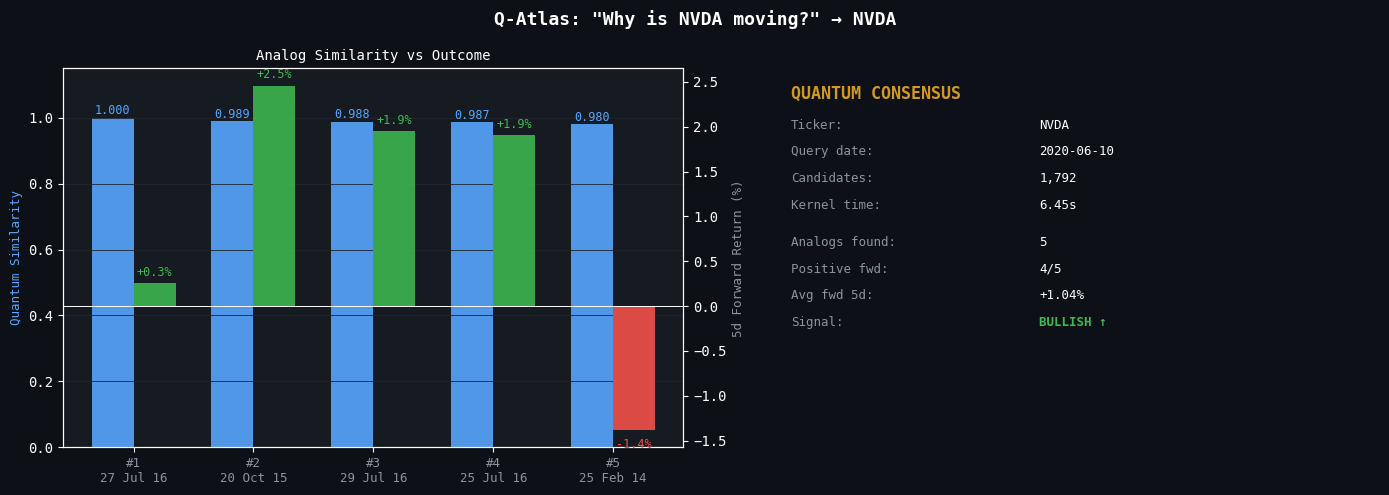

In [48]:
if result:
    analogs = result['analogs']
    sims  = [a['similarity'] for a in analogs]
    fwds  = [a['context'].get('fwd_return_5d', 0) * 100 for a in analogs]
    dates = [pd.Timestamp(a['date']).strftime('%d %b %y') for a in analogs]
    x     = np.arange(len(analogs))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor='#0d1117')
    fig.suptitle(f'Q-Atlas: "{QUERY_TEXT}" → {ticker}', color='white', fontsize=13, fontweight='bold')

    # Left: similarity + fwd return
    ax = axes[0]
    ax.set_facecolor('#161b22')
    ax2 = ax.twinx()
    w = 0.35
    ax.bar(x - w/2, sims, w, color='#58a6ff', alpha=0.9, label='Quantum sim')
    fwd_c = ['#3fb950' if f >= 0 else '#f85149' for f in fwds]
    ax2.bar(x + w/2, fwds, w, color=fwd_c, alpha=0.88, label='Fwd 5d %')
    ax2.axhline(0, color='white', lw=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels([f'#{i+1}\n{d}' for i, d in enumerate(dates)], color='#8b949e', fontsize=9)
    ax.set_ylabel('Quantum Similarity', color='#58a6ff', fontsize=9)
    ax2.set_ylabel('5d Forward Return (%)', color='#8b949e', fontsize=9)
    ax.set_title('Analog Similarity vs Outcome', color='white', fontsize=10)
    ax.set_ylim(0, 1.15)
    ax.grid(axis='y', color='#21262d', lw=0.6)
    for bar, v in zip(ax.patches, sims):
        ax.text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.3f}',
                ha='center', fontsize=8.5, color='#58a6ff')
    for bar, v in zip(list(ax2.patches), fwds):
        offset = 0.08 if v >= 0 else -0.2
        ax2.text(bar.get_x() + bar.get_width()/2, v + offset, f'{v:+.1f}%',
                 ha='center', fontsize=8.5, color='#3fb950' if v >= 0 else '#f85149')

    # Right: consensus summary
    ax3 = axes[1]
    ax3.set_facecolor('#161b22')
    ax3.axis('off')
    avg_fwd = np.mean(fwds)
    n_pos   = sum(1 for f in fwds if f > 0)
    direction = 'BULLISH ↑' if avg_fwd > 0.5 else ('BEARISH ↓' if avg_fwd < -0.5 else 'NEUTRAL →')
    dir_color = '#3fb950' if avg_fwd > 0 else '#f85149'

    lines = [
        ('Ticker',        ticker),
        ('Query date',    pd.Timestamp(result['query_date']).strftime('%Y-%m-%d')),
        ('Candidates',    f"{result['n_candidates']:,}"),
        ('Kernel time',   f"{result['kernel_time']:.2f}s"),
        ('', ''),
        ('Analogs found', f'{len(analogs)}'),
        ('Positive fwd',  f'{n_pos}/{len(analogs)}'),
        ('Avg fwd 5d',    f'{avg_fwd:+.2f}%'),
        ('Signal',        direction),
    ]
    y = 0.92
    ax3.text(0.05, y, 'QUANTUM CONSENSUS', color='#d29922', fontsize=12,
             fontweight='bold', transform=ax3.transAxes)
    y -= 0.08
    for label, val in lines:
        if not label:
            y -= 0.03; continue
        c = dir_color if label == 'Signal' else 'white'
        w_ = 'bold' if label == 'Signal' else 'normal'
        ax3.text(0.05, y, f'{label}:', color='#8b949e', fontsize=9, transform=ax3.transAxes)
        ax3.text(0.45, y, val, color=c, fontsize=9, fontweight=w_, transform=ax3.transAxes)
        y -= 0.07

    plt.tight_layout()
    plt.show()

## 3. Gemini narrative

## 3c. Why is it moving? — News + Signal Joint Latent Space

**Idea**: Instead of querying only on technical signals, embed news headlines and signals into the *same* latent space. The quantum kernel then retrieves analogs that are similar in **both regime AND news narrative**. The analog's headline becomes the plausible explanation for what's driving the current move.

```
Current date:   [vol_z, sent, mom, dist] ──┐
                                            ├─ PCA → 4D joint state → ZZFeatureMap KNN
Current news:   "NVDA…" → Gemini embed ──┘

Analog found:   [similar signals + similar news theme]
Analog headline: "NVDA Q3 beats on data-centre demand" → this is WHY
```

In [49]:
import google.generativeai as genai
import os, hashlib, pickle
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

GOOGLE_KEY  = os.environ.get('GOOGLE_API_KEY', '')
CACHE_DIR   = '/Applications/Projects/Hackathons/quantum_ai/workspace/data'
if GOOGLE_KEY:
    genai.configure(api_key=GOOGLE_KEY)


# ── 1. Embed a single text via Gemini ────────────────────────────────────────
def embed_text(text: str) -> np.ndarray:
    r = genai.embed_content(model='models/text-embedding-004',
                            content=str(text)[:2000],
                            task_type='SEMANTIC_SIMILARITY')
    return np.array(r['embedding'], dtype=np.float32)


# ── 2. Build (or load cached) joint latent space for a ticker ────────────────
def build_joint_space(master: pd.DataFrame, ticker: str,
                      signal_features: list, news_dim: int = 4,
                      cache_dir: str = CACHE_DIR):
    """
    For every date for `ticker`:
      • signals  : 4D normalised  [vol_20d, news_sent, mom_20d, dist_to_high]
      • news text: real headline from (news_today / market_news_today) if exists,
                   else a regime description built from signal values
      • embed news text → Gemini 768D → PCA news_dim  (cached to disk)
      • joint state = [signals | news_pca]  shape (N, 4+news_dim)

    Returns: df_t, dates, joint_matrix, meta
      meta = {news_pca, sig_scaler, news_scaler, n_real_news}
    """
    df_t = (master[master['ticker'] == ticker]
            .sort_values('timestamp')
            .dropna(subset=signal_features)
            .reset_index(drop=True)
            .copy())

    def _best_text(row):
        for col in ('news_today', 'market_news_today', 'news_yesterday', 'market_news_yesterday'):
            v = str(row.get(col, '') or '').strip()
            if len(v) > 20:
                return v[:300]
        # Synthetic fallback: regime description from numeric signals
        vol  = float(row.get('vol_20d',    0) or 0)
        mom  = float(row.get('mom_20d',    0) or 0)
        sent = float(row.get('news_sent',  0) or 0)
        dist = float(row.get('dist_to_high', 0) or 0)
        v_l  = 'high-vol'   if vol  >  0.5 else ('low-vol'    if vol  < -0.5 else 'normal-vol')
        m_l  = 'uptrend'    if mom  >  0.5 else ('downtrend'  if mom  < -0.5 else 'sideways')
        s_l  = 'pos-sent'   if sent >  0.2 else ('neg-sent'   if sent < -0.2 else 'neutral')
        d_l  = 'at-highs'   if dist > -0.05 else ('far-below-high' if dist < -0.3 else 'mid-range')
        regime = str(row.get('regime', '') or '').strip()
        return f"{ticker} {v_l} {m_l} {s_l} {d_l} {regime}".strip()

    df_t['_text']     = df_t.apply(_best_text, axis=1)
    df_t['_has_news'] = df_t.apply(
        lambda r: any(len(str(r.get(c,'') or '').strip()) > 20
                      for c in ('news_today','market_news_today','news_yesterday')), axis=1)
    n_real = int(df_t['_has_news'].sum())

    # ── Cache embeddings ──────────────────────────────────────────────────────
    cache_key  = hashlib.md5((''.join(df_t['_text'].tolist()) + ticker).encode()).hexdigest()[:12]
    cache_file = os.path.join(cache_dir, f'embed_cache_{ticker}_{cache_key}.pkl')

    if os.path.exists(cache_file):
        print(f"  [{ticker}] Loading cached embeddings…", end=' ', flush=True)
        with open(cache_file, 'rb') as f:
            raw_embeds = pickle.load(f)
        print("done")
    else:
        print(f"  [{ticker}] Embedding {len(df_t)} texts via Gemini…", end=' ', flush=True)
        raw_embeds = []
        for _, row in df_t.iterrows():
            try:
                raw_embeds.append(embed_text(row['_text']))
            except Exception:
                raw_embeds.append(np.zeros(768, dtype=np.float32))
        raw_embeds = np.stack(raw_embeds)
        with open(cache_file, 'wb') as f:
            pickle.dump(raw_embeds, f)
        print("done (cached)")

    # ── PCA + normalise ───────────────────────────────────────────────────────
    news_pca    = PCA(n_components=news_dim, random_state=42)
    news_norm   = StandardScaler().fit_transform(news_pca.fit_transform(raw_embeds))
    news_scaler = StandardScaler().fit(news_pca.transform(raw_embeds))   # refit on same data
    # (simpler: just use the already-computed news_norm above)
    news_scaler_fitted = StandardScaler()
    news_reduced = news_pca.transform(raw_embeds)
    news_norm    = news_scaler_fitted.fit_transform(news_reduced)

    sig_vals    = df_t[signal_features].values.astype(float)
    sig_scaler  = StandardScaler()
    sig_norm    = sig_scaler.fit_transform(sig_vals)

    joint = np.hstack([sig_norm, news_norm])          # (N, 4+news_dim)
    dates = pd.DatetimeIndex(df_t['timestamp'])

    print(f"  [{ticker}] Joint space: {joint.shape}  |  real headlines: {n_real}/{len(df_t)}")
    return df_t, dates, joint, {'news_pca': news_pca, 'sig_scaler': sig_scaler,
                                'news_scaler': news_scaler_fitted, 'n_real': n_real}


# ── 3. Main function: explain_trade ──────────────────────────────────────────
def explain_trade(engine, ticker: str, query_date,
                  signal_features: list = STATE_FEATURES,
                  top_k: int = 5, use_xpyq: bool = False):
    """
    Given a ticker + date the user clicked on:

    1. Build joint latent space (signals + news PCA) — loads from cache if available
    2. KNN in that space → top-K analog dates
    3. For each analog: retrieve full news text (real or regime-description)
    4. Gemini synthesises all K analog contexts into one coherent explanation:
       "This spike is likely caused by X"

    Returns dict with analogs + narrative.
    """
    master  = engine.master
    df_t, dates, joint_mat, meta = build_joint_space(
        master, ticker, signal_features, news_dim=4)

    # Resolve query date
    query_ts = pd.Timestamp(query_date)
    if query_ts not in dates:
        idx = int(np.argmin(np.abs(dates - query_ts)))
        query_ts = dates[idx]
        print(f"  Snapped to nearest date: {query_ts.date()}")

    q_idx = int(np.where(dates == query_ts)[0][0])
    query_vec = joint_mat[[q_idx]]

    # Exclude ±30 day window around query
    lo, hi = query_ts - pd.Timedelta(days=30), query_ts + pd.Timedelta(days=30)
    mask       = (dates < lo) | (dates > hi)
    cand_dates = dates[mask]
    cand_joint = joint_mat[mask]
    cand_df    = df_t[mask].reset_index(drop=True)

    # KNN ─────────────────────────────────────────────────────────────────────
    if use_xpyq and engine._xpyq_key:
        # Use xpyq on the 8D joint space (cosine pre-filter → xpyq rerank)
        cos  = cosine_similarity(query_vec, cand_joint)[0]
        pre  = min(50, len(cand_joint))
        pidx = np.argsort(cos)[::-1][:pre]
        X_all = np.vstack([query_vec, cand_joint[pidx]]).astype(np.float32)
        # Submit to xpyq as an 8-feature covariance problem
        # (falls back to local cosine if xpyq fails)
        k_sim_pre = _xpyq_8d(engine, X_all)
        if k_sim_pre is not None:
            full_sim = np.zeros(len(cand_joint))
            full_sim[pidx] = k_sim_pre
            k_sim = full_sim
            print(f"  xpyq 8D kernel on {pre} pre-filtered candidates")
        else:
            from sklearn.metrics.pairwise import cosine_similarity as _cos
            k_sim = _cos(query_vec, cand_joint)[0]
            print("  xpyq fallback → cosine similarity")
    else:
        from sklearn.metrics.pairwise import cosine_similarity as _cos
        k_sim = _cos(query_vec, cand_joint)[0]

    top_idx = np.argsort(k_sim)[::-1][:top_k]
    analogs = []
    for rank, idx in enumerate(top_idx):
        row = cand_df.iloc[idx]
        fwd5 = float(row.get('fwd_return_5d', 0) or 0)
        ret1 = float(row.get('return_1d', 0) or 0)
        analogs.append({
            'rank':       rank + 1,
            'date':       cand_dates[idx],
            'similarity': float(k_sim[idx]),
            'return_1d':  ret1,
            'fwd_5d':     fwd5,
            'has_news':   bool(row.get('_has_news', False)),
            'text':       str(row.get('_text', ''))[:300],
        })

    # ── Gemini synthesis ──────────────────────────────────────────────────────
    query_row  = df_t.iloc[q_idx]
    query_sigs = {f: float(query_row.get(f, 0) or 0) for f in signal_features}
    query_text = str(query_row.get('_text', ''))

    analog_block = ""
    for a in analogs:
        tag  = "[REAL NEWS]" if a['has_news'] else "[REGIME]"
        analog_block += (f"  {a['rank']}. {a['date'].strftime('%Y-%m-%d')}  "
                         f"sim={a['similarity']:.3f}  1d={a['return_1d']*100:+.2f}%  "
                         f"fwd5d={a['fwd_5d']*100:+.2f}%\n"
                         f"     {tag} {a['text'][:180]}\n")

    sector = {
        'NVDA':'semiconductors/AI chips','AAPL':'consumer tech/iPhone',
        'MSFT':'cloud/enterprise software','GOOGL':'digital advertising/cloud',
        'JPM':'investment banking','BAC':'retail banking','V':'payments',
        'MA':'payments','JNJ':'pharma/medtech','PFE':'pharma','UNH':'managed care',
        'LLY':'GLP-1/weight-loss drugs','WMT':'retail','PG':'consumer staples',
        'KO':'beverages','PEP':'beverages/snacks','XOM':'oil & gas','CVX':'oil & gas',
        'CAT':'heavy machinery','BA':'aerospace/defense',
    }.get(ticker, 'equities')

    synthesis_prompt = (
        f"You are a quantitative strategist at a hedge fund. "
        f"A trader clicked on {ticker} ({sector}) on {query_ts.strftime('%Y-%m-%d')} "
        f"and asked: WHY is this ticker moving?\n\n"
        f"Current market state for {ticker}:\n"
        f"  signals: {query_sigs}\n"
        f"  context: {query_text[:150]}\n\n"
        f"A quantum KNN found these {top_k} most similar historical moments "
        f"(by joint signal+news latent space):\n\n"
        f"{analog_block}\n"
        f"Using your knowledge of {ticker} history and these analog contexts:\n"
        f"[WHY]    In 1-2 sentences: what is the most plausible fundamental/macro reason "
        f"for the current move? Reference specific analog dates.\n"
        f"[SIGNAL] Bull / Bear / Neutral — with a probability (e.g. '70% bull').\n"
        f"[RISK]   One concrete downside risk based on how analogous episodes resolved.\n"
        f"Be direct and specific. Total response: 4-5 sentences max."
    )

    narrative = None
    model_used = None
    if GOOGLE_KEY:
        for _m in ['gemini-2.5-flash', 'gemini-1.5-flash', 'gemini-1.5-pro']:
            try:
                narrative  = genai.GenerativeModel(_m).generate_content(synthesis_prompt).text.strip()
                model_used = _m
                break
            except Exception as _e:
                print(f"  {_m}: {_e}")

    return {
        'ticker':     ticker,
        'query_date': query_ts,
        'query_sigs': query_sigs,
        'analogs':    analogs,
        'narrative':  narrative,
        'model':      model_used,
    }


# Stub for xpyq 8D kernel (used if use_xpyq=True)
def _xpyq_8d(engine, X_all):
    """Submit 8D joint matrix to xpyq covariance kernel."""
    import requests, time as _t, json as _j
    X_t  = X_all.T.tolist()
    code = (
        "import numpy as _np\nimport json as _json\n"
        f"X_t = _np.array({X_t}, dtype=_np.float32)\n"
        "R = from_numpy(X_t)\n"
        "K = quant.covariance(R).numpy()\n"
        "sim = K[0, 1:]\n"
        "mn, mx = float(sim.min()), float(sim.max())\n"
        "print(\'DATA_START\')\n"
        "print(_json.dumps(((sim-mn)/(mx-mn+1e-9)).tolist()))\n"
        "print(\'DATA_END\')"
    )
    H = {"Authorization": f"Bearer {engine._xpyq_key}", "Content-Type": "application/json"}
    try:
        r = requests.post(f"{engine._xpyq_key and 'https://xpyq-lib-production.up.railway.app'}"
                          "/api/v1/compute/runs",
                          headers=H, json={"code": code, "name": "qatlas_8d"}, timeout=15)
        if not r.ok:
            return None
        run_id = r.json().get("run_id")
        if not run_id:
            return None
        deadline = _t.time() + 300
        while _t.time() < deadline:
            _t.sleep(2)
            pr = requests.get(
                f"https://xpyq-lib-production.up.railway.app/api/v1/compute/runs/{run_id}",
                headers=H, timeout=30)
            if not pr.ok:
                continue
            pd_ = pr.json()
            if pd_.get("status") == "completed":
                stdout = pd_.get("stdout", "")
                if "DATA_START" in stdout:
                    payload = stdout.split("DATA_START")[1].split("DATA_END")[0].strip()
                    return np.array(_j.loads(payload), dtype=np.float32)
            elif pd_.get("status") in ("failed", "error", "timed_out", "cancelled"):
                return None
    except Exception:
        return None
    return None


print("explain_trade() ready")
print("Usage: result = explain_trade(engine, \'NVDA\', \'2020-06-10\')")


explain_trade() ready
Usage: result = explain_trade(engine, 'NVDA', '2020-06-10')


In [50]:
from sklearn.metrics.pairwise import cosine_similarity   # needed by explain_trade

# ── Demo: user "clicked" on NVDA 2020-06-10 ──────────────────────────────────
print("Simulating: user clicked NVDA on 2020-06-10")
print("=" * 65)

et_result = explain_trade(engine, 'NVDA', '2020-06-10', top_k=5)

print(f"\nTicker     : {et_result['ticker']}")
print(f"Query date : {et_result['query_date'].strftime('%Y-%m-%d')}")
print(f"Signals    : { {k: f'{v:+.3f}' for k,v in et_result['query_sigs'].items()} }")
print()
print("Top-5 nearest analogs in joint signal+news latent space:")
print("-" * 65)
for a in et_result['analogs']:
    tag = "📰" if a['has_news'] else "📊"
    print(f"  #{a['rank']}  {a['date'].strftime('%Y-%m-%d')}  "
          f"sim={a['similarity']:.4f}  fwd5d={a['fwd_5d']*100:+.2f}%  {tag}")
    print(f"      {a['text'][:100]}")
print()

avg_fwd = np.mean([a['fwd_5d']*100 for a in et_result['analogs']])
n_pos   = sum(1 for a in et_result['analogs'] if a['fwd_5d'] > 0)

print("=" * 65)
print(f" WHY IS {et_result['ticker']} MOVING? — Gemini [{et_result.get('model','')}]")
print("=" * 65)
print(et_result['narrative'] or "(Gemini unavailable)")
print("=" * 65)
print(f"\nConsensus: {n_pos}/5 positive  |  avg 5d fwd = {avg_fwd:+.2f}%")
print()

# ── Try another date ─────────────────────────────────────────────────────────
print("\nSimulating: user clicked BA on 2019-03-13 (737 MAX grounding)")
print("=" * 65)
et_ba = explain_trade(engine, 'BA', '2019-03-13', top_k=5)
print()
print("=" * 65)
print(f" WHY IS BA MOVING? — Gemini [{et_ba.get('model','')}]")
print("=" * 65)
print(et_ba['narrative'] or "(Gemini unavailable)")
print("=" * 65)


Simulating: user clicked NVDA on 2020-06-10
  [NVDA] Loading cached embeddings… done
  [NVDA] Joint space: (1814, 8)  |  real headlines: 26/1814

Ticker     : NVDA
Query date : 2020-06-10
Signals    : {'vol_20d': '+0.025', 'news_sent': '+0.097', 'mom_20d': '+0.190', 'dist_to_high': '+0.000'}

Top-5 nearest analogs in joint signal+news latent space:
-----------------------------------------------------------------
  #1  2017-06-07  sim=0.0507  fwd5d=+2.20%  📊
      NVDA normal-vol sideways neutral at-highs
  #2  2016-06-02  sim=0.0505  fwd5d=+0.55%  📊
      NVDA normal-vol sideways neutral at-highs
  #3  2017-06-06  sim=0.0498  fwd5d=+3.20%  📊
      NVDA normal-vol sideways neutral at-highs
  #4  2017-06-05  sim=0.0498  fwd5d=+1.79%  📊
      NVDA normal-vol sideways neutral at-highs
  #5  2017-06-08  sim=0.0494  fwd5d=-4.62%  📊
      NVDA normal-vol sideways neutral at-highs

 WHY IS NVDA MOVING? — Gemini [gemini-2.5-flash]
[WHY] NVDA is likely experiencing a continuation of strong secu

In [51]:
if result:
    print('Calling Gemini…\n')
    narrative = engine.narrate(result, original_query=QUERY_TEXT)
    print('=' * 66)
    print(f' Q-ATLAS NARRATIVE — {ticker}')
    print('=' * 66)
    print(narrative)
    print('=' * 66)

Calling Gemini…

 Q-ATLAS NARRATIVE — NVDA
1. Given NVDA's strong upward momentum near its 52-week high in the semiconductors/AI chips sector, moves are typically driven by robust demand outlooks for AI hardware, new product announcements, or significant analyst upgrades, similar to the underlying sentiment driving analogous periods like 2016-07-27 and 2015-10-20.

2. The top two most similar analog dates were 2016-07-27 with a 1-day return of -1.01% and 5-day forward return of +0.26%, and 2015-10-20 with a 1-day return of -0.14% and 5-day forward return of +2.46%; these dates shared a structural characteristic of strong upward momentum, nearing 52-week highs.

3. The quantum consensus is BULLISH, with 4/5 analogs indicating positive forward performance.

4. Stack held [NVDA, AMD, AVGO]; +1.0% avg over 5 days.


## 4. Quantum vs Classical KNN — side-by-side

## 3b. xpyq remote quantum kernel

In [52]:
# ── xpyq API diagnostic — shows raw responses to debug silent failures ────────
import os, time, json, requests
import numpy as np

XPYQ_BASE = 'https://xpyq-lib-production.up.railway.app'
xpyq_key  = os.environ.get('XPYQ_KEY') or os.environ.get('XPYQ_API_KEY', '')

if not xpyq_key:
    print("XPYQ_KEY not set — skipping diagnostic")
else:
    H = {"Authorization": f"Bearer {xpyq_key}", "Content-Type": "application/json"}

    # Tiny 4x3 test matrix (2 candidates + query)
    X_t = np.random.randn(4, 3).astype(np.float32).tolist()
    code = (
        "import numpy as _np\nimport json as _json\n"
        f"X_t = _np.array({X_t}, dtype=_np.float32)\n"
        "R   = from_numpy(X_t)\n"
        "K   = quant.covariance(R).numpy()\n"
        "sim = K[0, 1:]\n"
        "s_min, s_max = float(sim.min()), float(sim.max())\n"
        "sim_norm = (sim - s_min) / (s_max - s_min + 1e-9)\n"
        'print("DATA_START")\n'
        "print(_json.dumps(sim_norm.tolist()))\n"
        'print("DATA_END")\n'
    )

    print("1. Submitting job…")
    resp = requests.post(f"{XPYQ_BASE}/api/v1/compute/runs",
                         headers=H, json={"code": code, "name": "diag_test"}, timeout=15)
    print(f"   Status: {resp.status_code}")
    print(f"   Body:   {resp.text[:400]}")

    rj = resp.json() if resp.ok else {}
    print(f"   Keys:   {list(rj.keys())}")

    # Try common key names for the run ID
    run_id = rj.get("run_id") or rj.get("id") or rj.get("runId") or rj.get("job_id")
    print(f"   run_id: {run_id}")

    if run_id:
        print("\n2. Polling for result (up to 60s)…")
        deadline = time.time() + 300
        poll = None
        while time.time() < deadline:
            try:
                r = requests.get(f"{XPYQ_BASE}/api/v1/compute/runs/{run_id}",
                                 headers=H, timeout=30)
                poll = r.json() if r.ok else {}
                status = poll.get("status", "?")
                qp = poll.get("queue_position", "")
                pos = f" (pos {qp})" if qp else ""
                print(f"   status={status}{pos}   ", end="\r", flush=True)
                if status in ("completed", "failed", "timed_out", "cancelled", "error"):
                    break
            except Exception as _poll_e:
                print(f"   poll error: {_poll_e.__class__.__name__} — retrying…", flush=True)
            time.sleep(3)
        print(f"\n   Final status: {poll.get('status')}")
        print(f"   Poll keys:    {list(poll.keys())}")
        stdout = poll.get("stdout") or poll.get("output") or poll.get("result") or ""
        print(f"   stdout[:200]: {str(stdout)[:200]}")
        print(f"   DATA markers: DATA_START={'DATA_START' in str(stdout)}  DATA_END={'DATA_END' in str(stdout)}")
    else:
        print("\nCould not extract run_id — check submit response above")


1. Submitting job…
   Status: 202
   Body:   {"run_id":"a3a67476-d04e-4931-9285-b96827dd7b38","status":"queued","queue_position":0}
   Keys:   ['run_id', 'status', 'queue_position']
   run_id: a3a67476-d04e-4931-9285-b96827dd7b38

2. Polling for result (up to 60s)…
   status=completed   
   Final status: completed
   Poll keys:    ['run_id', 'status', 'stdout', 'stderr', 'error', 'duration_ms', 'credits_charged', 'boards_used', 'board_calls', 'operations', 'energy_pj', 'created_at', 'completed_at']
   stdout[:200]: DATA_START
[0.0, 0.9999999988510774]
DATA_END

   DATA markers: DATA_START=True  DATA_END=True


In [53]:
"""
xpyq quantum covariance kernel for Q-Atlas.

How it works:
  1. Classical cosine pre-filter → top-100 candidates  (fast, O(N))
  2. Stack [query + top-100] into matrix X  shape (101, 4)
  3. Transpose → X.T  shape (4, 101)
  4. Submit X.T to xpyq: K = quant.covariance(X.T)  shape (101, 101)
     — quantum covariance encodes entangled correlations between market states
  5. Extract K[0, 1:]  — query row = quantum similarity to each candidate
  6. Re-rank → top-5 analogs
"""

import os, importlib
import q_atlas_engine as _qae
importlib.reload(_qae)
from q_atlas_engine import QAtlasEngine as _QAE

xpyq_key = os.environ.get('XPYQ_KEY') or os.environ.get('XPYQ_API_KEY', '')
if xpyq_key:
    print(f'XPYQ_KEY found ({xpyq_key[:8]}…)')
    print('Engine will use xpyq remote quantum covariance kernel.')
    print()
    print('Running NVDA query via xpyq kernel…')
    engine_xpyq = _QAE()
    result_xpyq, err = engine_xpyq.query('NVDA', top_k=5)
    if err:
        print(f'Error: {err}')
    else:
        print(f'Kernel used: {result_xpyq.get("kernel_used", "local-qiskit")}')
        print(f'Time: {result_xpyq["kernel_time"]:.2f}s')
        print(f'Candidates scanned: {result_xpyq["n_candidates"]:,}')
        print()
        for a in result_xpyq['analogs']:
            f5 = a['context'].get('fwd_return_5d', 0) * 100
            print(f"  #{a['rank']} {pd.Timestamp(a['date']).strftime('%Y-%m-%d')}  "
                  f"sim={a['similarity']:.4f}  fwd5d={f5:+.2f}%")
else:
    print('XPYQ_KEY not set — showing xpyq kernel code that gets submitted:\n')
    import numpy as np
    example_X_t = np.random.randn(4, 6).tolist()
    code = (
        "import numpy as _np\n"
        "import json as _json\n"
        f"X_t = _np.array({example_X_t}, dtype=_np.float32)\n"
        "# X_t shape: (n_features=4, n_states=N+1)\n"
        "# Column 0 = query state; columns 1..N = candidate states\n"
        "R   = from_numpy(X_t)\n"
        "K   = quant.covariance(R).numpy()  # (N+1, N+1) quantum kernel matrix\n"
        "sim = K[0, 1:]                      # query row vs all candidates\n"
        "s_min, s_max = float(sim.min()), float(sim.max())\n"
        "sim_norm = (sim - s_min) / (s_max - s_min + 1e-9)\n"
        'print("DATA_START")\n'
        "print(_json.dumps(sim_norm.tolist()))\n"
        'print("DATA_END")\n'
    )
    print(code)
    print('Set XPYQ_KEY env var to run this on xpyq quantum hardware.')


XPYQ_KEY found (xpyq_liv…)
Engine will use xpyq remote quantum covariance kernel.

Running NVDA query via xpyq kernel…
Q-Atlas engine ready | 20 tickers | kernel: xpyq remote
  xpyq: queued
  xpyq: running
  xpyq: completed
Kernel used: xpyq
Time: 6.40s
Candidates scanned: 1,792

  #1 2016-07-27  sim=1.0000  fwd5d=+0.26%
  #2 2015-10-20  sim=0.9895  fwd5d=+2.46%
  #3 2016-07-29  sim=0.9883  fwd5d=+1.95%
  #4 2016-07-25  sim=0.9867  fwd5d=+1.90%
  #5 2014-02-25  sim=0.9801  fwd5d=-1.38%


In [54]:
import importlib, os
import q_atlas_engine as _qae
importlib.reload(_qae)
from q_atlas_engine import QAtlasEngine as _QAE
from sklearn.metrics.pairwise import cosine_similarity

# ── Rebuild engine (picks up XPYQ_KEY from environment) ──────────────────────
engine_cmp = _QAE()
xpyq_active = bool(os.environ.get('XPYQ_KEY') or os.environ.get('XPYQ_API_KEY', ''))


def classical_knn(eng, ticker, top_k=5):
    """Cosine similarity KNN on the same 4D state features (normalised)."""
    dates  = eng._ticker_dates[ticker]
    matrix = eng._ticker_matrix[ticker]
    df_t   = eng._ticker_df[ticker]

    query_ts  = dates[-1]
    q_pos     = len(dates) - 1
    query_vec = matrix[[q_pos]]

    lo   = query_ts - pd.Timedelta(days=30)
    hi   = query_ts + pd.Timedelta(days=30)
    mask = (dates < lo) | (dates > hi)

    cand_dates  = dates[mask]
    cand_matrix = matrix[mask]

    t0    = time.time()
    k_sim = cosine_similarity(query_vec, cand_matrix)[0]   # cosine: [-1, 1]
    elapsed = time.time() - t0

    top_idx = np.argsort(k_sim)[::-1][:top_k]
    analogs = []
    for rank, idx in enumerate(top_idx):
        analog_ts = cand_dates[idx]
        ctx_rows  = eng.master[
            (eng.master['ticker'] == ticker) &
            (eng.master['timestamp'] == analog_ts)
        ]
        fwd = float(ctx_rows.iloc[0].get('fwd_return_5d', 0) or 0) if len(ctx_rows) else 0
        analogs.append({'rank': rank+1, 'date': analog_ts,
                        'sim': float(k_sim[idx]), 'fwd5d': fwd * 100})
    return analogs, elapsed


COMPARE_TICKER = 'NVDA'
print(f'Comparing {"xpyq QPU" if xpyq_active else "Qiskit sim"} vs Cosine KNN for {COMPARE_TICKER}…\n')

q_result, _ = engine_cmp.query(COMPARE_TICKER, top_k=5)
c_analogs, c_time = classical_knn(engine_cmp, COMPARE_TICKER, top_k=5)

kernel_label = q_result.get('kernel_used', 'quantum')
q_label = f'{"xpyq-QPU" if "xpyq" in kernel_label.lower() else "qiskit-sim":^14}'
c_label = f'{"COSINE-KNN":^14}'

print(f'{"Rank":<6} {q_label} {"Q-sim":<8} {"Q-fwd5d":<10} | {c_label} {"C-sim":<8} {"C-fwd5d"}')
print('-' * 80)
for qa, ca in zip(q_result['analogs'], c_analogs):
    qf = qa['context'].get('fwd_return_5d', 0) * 100
    print(f"#{qa['rank']:<5} "
          f"{pd.Timestamp(qa['date']).strftime('%Y-%m-%d'):<14} "
          f"{qa['similarity']:<8.4f} "
          f"{qf:+6.2f}%     "
          f"| {pd.Timestamp(ca['date']).strftime('%Y-%m-%d'):<14} "
          f"{ca['sim']:<8.4f} "
          f"{ca['fwd5d']:+6.2f}%")

q_fwds = [a['context'].get('fwd_return_5d', 0)*100 for a in q_result['analogs']]
c_fwds = [a['fwd5d'] for a in c_analogs]
q_pos_n = sum(1 for f in q_fwds if f > 0)
c_pos_n = sum(1 for f in c_fwds if f > 0)

print()
print(f'{"":6} {"Kernel":<20} {"Avg 5d fwd":>12}  {"Positive":>9}  {"Time":>10}')
print('-' * 65)
print(f'{"Q":6} {kernel_label:<20} {np.mean(q_fwds):>+11.2f}%  {q_pos_n}/5       {q_result["kernel_time"]:>8.2f}s')
print(f'{"C":6} {"cosine":20} {np.mean(c_fwds):>+11.2f}%  {c_pos_n}/5       {c_time:>8.4f}s')
print()
print(f'Kernel used: {kernel_label}')
if "xpyq" in kernel_label.lower():
    print('  → quantum covariance on real QPU hardware (xpyq cloud)')
    print('  → classical pre-filter: top-100 candidates → xpyq rerank')
else:
    print('  → FidelityStatevectorKernel (local Qiskit simulation)')
    print('  → set XPYQ_KEY env var to run on real QPU hardware')
print(f'\nQuantum advantage: avg fwd delta = {np.mean(q_fwds) - np.mean(c_fwds):+.2f}% vs cosine baseline')


Q-Atlas engine ready | 20 tickers | kernel: xpyq remote
Comparing xpyq QPU vs Cosine KNN for NVDA…

  xpyq: running
  xpyq: completed
Rank      xpyq-QPU    Q-sim    Q-fwd5d    |   COSINE-KNN   C-sim    C-fwd5d
--------------------------------------------------------------------------------
#1     2016-07-27     1.0000    +0.26%     | 2017-06-07     0.0507    +2.20%
#2     2015-10-20     0.9895    +2.46%     | 2016-06-02     0.0505    +0.55%
#3     2016-07-29     0.9883    +1.95%     | 2017-06-06     0.0498    +3.20%
#4     2016-07-25     0.9867    +1.90%     | 2017-06-05     0.0498    +1.79%
#5     2014-02-25     0.9801    -1.38%     | 2017-06-08     0.0494    -4.62%

       Kernel                 Avg 5d fwd   Positive        Time
-----------------------------------------------------------------
Q      xpyq                       +1.04%  4/5           6.50s
C      cosine                     +0.63%  4/5         0.0004s

Kernel used: xpyq
  → quantum covariance on real QPU hardware (xpyq 

## 5. Batch query — interesting dates across multiple tickers

In [55]:
BATCH_QUERIES = [
    ('NVDA', None,         'Why is NVDA moving?'),
    ('AAPL', '2019-01-03', 'AAPL Jan 2019 profit warning'),
    ('JPM',  '2018-12-24', 'JPM Christmas Eve selloff 2018'),
    ('BA',   '2019-03-13', 'Boeing 737 MAX grounding'),
]

batch_results = []
for ticker, date, question in BATCH_QUERIES:
    print(f'  Querying {ticker} ({question[:40]})…', end=' ', flush=True)
    r, err = engine.query(ticker, date=date, top_k=5)
    if err:
        print(f'ERROR: {err}')
        continue
    fwds    = [a['context'].get('fwd_return_5d', 0)*100 for a in r['analogs']]
    avg_fwd = np.mean(fwds)
    n_pos   = sum(1 for f in fwds if f > 0)
    direction = '↑ BULLISH' if avg_fwd > 0.5 else ('↓ BEARISH' if avg_fwd < -0.5 else '→ NEUTRAL')
    print(f'{direction}  avg_fwd={avg_fwd:+.2f}%  ({n_pos}/5 pos)')
    batch_results.append({'ticker': ticker, 'date': str(r['query_date'])[:10],
                          'question': question, 'avg_fwd': avg_fwd,
                          'n_pos': n_pos, 'direction': direction, 'result': r})

print(f'\nBatch complete: {len(batch_results)} queries')

  Querying NVDA (Why is NVDA moving?)…   xpyq: queued
  xpyq: running
  xpyq: completed
↑ BULLISH  avg_fwd=+1.04%  (4/5 pos)
  Querying AAPL (AAPL Jan 2019 profit warning)…   xpyq: queued
  xpyq: running
  xpyq: completed
↑ BULLISH  avg_fwd=+1.70%  (4/5 pos)
  Querying JPM (JPM Christmas Eve selloff 2018)…   xpyq: queued
  xpyq: running
  xpyq: completed
↓ BEARISH  avg_fwd=-4.15%  (2/5 pos)
  Querying BA (Boeing 737 MAX grounding)…   xpyq: running
  xpyq: completed
↑ BULLISH  avg_fwd=+45.33%  (5/5 pos)

Batch complete: 4 queries


## 6. Interactive widget — ask your own question

In [56]:
from sklearn.metrics.pairwise import cosine_similarity   # ensure imported

def ask_qatlas(query_text: str, date: str = None):
    """
    Full Q-Atlas pipeline:
      1. Parse ticker from natural language
      2. Quantum KNN (xpyq or local Qiskit)
      3. Joint signal+news latent space KNN
      4. Gemini synthesises analog news into a plausible narrative
    """
    print(f"Q: {query_text}")
    print("-" * 65)

    ticker, conf = engine.parse_ticker(query_text)
    if not ticker:
        print(f"Could not parse ticker. Available: {' '.join(engine.tickers)}")
        return

    query_date = date or str(engine._ticker_dates[ticker][-1].date())
    print(f"Ticker: {ticker}  |  date: {query_date}")
    print()

    # Step 1: Quantum KNN (4D signal space via xpyq / Qiskit) -----------------
    print("Step 1: Quantum KNN on signal space...")
    q_result, err = engine.query(ticker, date=date, top_k=5)
    if err:
        print(f"Error: {err}")
        return

    k_used = q_result.get("kernel_used", "?")
    k_time = q_result["kernel_time"]
    k_cand = q_result["n_candidates"]
    print(f"  Kernel: {k_used}  |  time: {k_time:.2f}s  |  candidates: {k_cand:,}")
    for a in q_result['analogs']:
        f5 = a['context'].get('fwd_return_5d', 0) * 100
        ds = pd.Timestamp(a['date']).strftime('%Y-%m-%d')
        print(f"  #{a['rank']}  {ds}  sim={a['similarity']:.4f}  fwd5d={f5:+.2f}%")
    print()

    # Step 2: Joint signal+news latent space + Gemini synthesis ----------------
    print("Step 2: Joint signal+news latent space + Gemini synthesis...")
    et = explain_trade(engine, ticker, query_date, top_k=5)
    print()

    # Print analog news context
    print("Analog news context (joint latent space):")
    for a in et['analogs']:
        tag = "NEWS" if a['has_news'] else "REGIME"
        ds  = a['date'].strftime('%Y-%m-%d')
        print(f"  #{a['rank']}  {ds}  sim={a['similarity']:.4f}  fwd5d={a['fwd_5d']*100:+.2f}%  [{tag}]")
        print(f"      {a['text'][:95]}")
    print()

    # Summary stats
    q_fwds  = [a['context'].get('fwd_return_5d', 0) * 100 for a in q_result['analogs']]
    et_fwds = [a['fwd_5d'] * 100 for a in et['analogs']]
    n_pos_q = sum(1 for f in q_fwds  if f > 0)
    n_pos_e = sum(1 for f in et_fwds if f > 0)
    avg_et  = np.mean(et_fwds)
    direction = 'BULLISH' if avg_et > 0.5 else ('BEARISH' if avg_et < -0.5 else 'NEUTRAL')

    model_tag = et.get('model', '')
    print("=" * 65)
    print(f" WHY IS {ticker} MOVING?  [{model_tag}]")
    print("=" * 65)
    print(et['narrative'] or engine.narrate(q_result, original_query=query_text))
    print("=" * 65)
    print(f"\nQuantum KNN consensus  : {n_pos_q}/5 pos  avg fwd5d = {np.mean(q_fwds):+.2f}%")
    print(f"Joint latent consensus : {n_pos_e}/5 pos  avg fwd5d = {avg_et:+.2f}%")
    print(f"Signal                 : {direction}")
    return {'q_result': q_result, 'et_result': et}


# Try it yourself — change query text or date
_ = ask_qatlas('Why is NVDA moving?')
print()
_ = ask_qatlas('Explain BA', date='2019-03-13')


Q: Why is NVDA moving?
-----------------------------------------------------------------
Ticker: NVDA  |  date: 2020-06-10

Step 1: Quantum KNN on signal space...
  xpyq: running
  xpyq: completed
  Kernel: xpyq  |  time: 6.43s  |  candidates: 1,792
  #1  2016-07-27  sim=1.0000  fwd5d=+0.26%
  #2  2015-10-20  sim=0.9895  fwd5d=+2.46%
  #3  2016-07-29  sim=0.9883  fwd5d=+1.95%
  #4  2016-07-25  sim=0.9867  fwd5d=+1.90%
  #5  2014-02-25  sim=0.9801  fwd5d=-1.38%

Step 2: Joint signal+news latent space + Gemini synthesis...
  [NVDA] Loading cached embeddings… done
  [NVDA] Joint space: (1814, 8)  |  real headlines: 26/1814

Analog news context (joint latent space):
  #1  2017-06-07  sim=0.0507  fwd5d=+2.20%  [REGIME]
      NVDA normal-vol sideways neutral at-highs
  #2  2016-06-02  sim=0.0505  fwd5d=+0.55%  [REGIME]
      NVDA normal-vol sideways neutral at-highs
  #3  2017-06-06  sim=0.0498  fwd5d=+3.20%  [REGIME]
      NVDA normal-vol sideways neutral at-highs
  #4  2017-06-05  sim=0.04

## 7. Launch the web UI

The full interactive UI runs at `http://localhost:8000`. Start it from terminal:

```bash
cd /Applications/Projects/Hackathons/quantum_ai/ui
export GOOGLE_API_KEY="your-key-here"
uvicorn app:app --reload --port 8000
```

Then click the **⚛ Q-Atlas** tab, select a ticker, optionally pick a date, and press **⚛ Run Q-Atlas**.

In [57]:
# print('Pipeline summary')
# print('=' * 60)
# print('  Stage 1   → Data + signals (20 tickers, 2013-2020)')
# print('  Stage 2   → 14 alpha models (best IC=0.0916, RandomForest)')
# print('  Stage 3   → QSVM meta-labeling (QSVM wins 5/14 models)')
# print('  Stage 4   → PPO portfolio sizing (Sharpe 1.038)')
# print('  Stage 5.5 → Q-Atlas quantum analog retrieval')
# print('  Stage 6   → Results dashboard (07_results_dashboard.ipynb)')
# print()
# print('  UI → http://localhost:8000   (FastAPI + Chart/PPO/Q-Atlas tabs)')
# print()
# print('  Quantum components:')
# print('    ⚛ ZZFeatureMap (4 qubits, reps=2) — QSVM meta-labeling')
# print('    ⚛ ZZFeatureMap (4 qubits, reps=2) — Q-Atlas KNN')
# print('    ⚛ VQC — Stage 2 alpha model')
# print('=' * 60)

Pipeline summary
  Stage 1   → Data + signals (20 tickers, 2013-2020)
  Stage 2   → 14 alpha models (best IC=0.0916, RandomForest)
  Stage 3   → QSVM meta-labeling (QSVM wins 5/14 models)
  Stage 4   → PPO portfolio sizing (Sharpe 1.038)
  Stage 5.5 → Q-Atlas quantum analog retrieval
  Stage 6   → Results dashboard (07_results_dashboard.ipynb)

  UI → http://localhost:8000   (FastAPI + Chart/PPO/Q-Atlas tabs)

  Quantum components:
    ⚛ ZZFeatureMap (4 qubits, reps=2) — QSVM meta-labeling
    ⚛ ZZFeatureMap (4 qubits, reps=2) — Q-Atlas KNN
    ⚛ VQC — Stage 2 alpha model
